# Лабораторна робота №3
## Оптимізація гіперпараметрів, вкладена крос-валідація та дослідження витоку даних (Data Leakage)

Мета: навчитися застосовувати методи оптимізації гіперпараметрів і крос-валідації; дослідити вплив вибору алгоритму пошуку на обчислювальну складність і якість моделей; опанувати методологію запобігання витоку даних та вкладеної крос-валідації (Nested CV).

Дані: `data/bedtime_screentime_sleep_debt.csv` - 8500 спостережень, 12 числових і 4 категоріальні ознаки, 4 незбалансовані класи (`sleep_debt_category`).

Модель: `RandomForestClassifier` - обрана в лабораторній №2, має багато гіперпараметрів і схильна до перенавчання.

Метрика: `f1_macro` - класи незбалансовані (4462 / 2004 / 1387 / 647), тому accuracy тут оманлива.

### Структура роботи
1. Підготовка даних, внесення контрольованого шуму та baseline-модель.
2. Дослідження 1: Full Grid Search vs Random Search (N=20, 50) vs Bayesian Optimization (Optuna TPE, N=20).
3. Дослідження 2: коректний пайплайн vs пайплайн із витоком даних.
4. Дослідження 3: Nested Cross-Validation (зовнішня петля K=5, внутрішня K=3).

> Про шум. Датасет синтетичний: цільова змінна є детермінованою (майже) функцією ознак, тому наївна модель дає F1 ≈ 1.0 і будь-яке порівняння методів оптимізації втрачає сенс. Щоб отримати реалістичний рівень якості, у числові ознаки вноситься гауссів шум. Рівень шуму підбирається емпірично нижче так, щоб модель із типовими гіперпараметрами давала F1 ≤ 0.83.

## 1. Імпорти та налаштування

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV,
    cross_val_score,
)
from sklearn.metrics import f1_score, classification_report, confusion_matrix

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

RANDOM_STATE = 42
TEST_SIZE = 0.33
NOISE_SCALE = 0.25
SCORING = 'f1_macro'
N_JOBS = -1

print('pandas', pd.__version__, '| sklearn', __import__('sklearn').__version__, '| optuna', optuna.__version__)

pandas 3.0.6 | sklearn 1.9.1 | optuna 5.0.0


## 2. Дані та розбиття на train/test

Розбиття виконується до будь-якого навчання препроцесорів. Тестова частина не використовується ніде, крім фінальних оцінок.

In [2]:
df = pd.read_csv('data/bedtime_screentime_sleep_debt.csv')
df = df.dropna().drop_duplicates().drop(columns=['user_id'])

TARGET = 'sleep_debt_category'
X = df.drop(columns=TARGET)
y = df[TARGET]

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(include='str').columns.tolist()

print(f'{X.shape[0]} рядків, {X.shape[1]} ознак (числових: {len(num_cols)}, категоріальних: {len(cat_cols)})')

cls = y.value_counts()
display(pd.DataFrame({'клас': cls.index, 'n': cls.values, 'частка': (cls / len(y)).round(3)}))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print(f'train: {X_train.shape[0]} | test: {X_test.shape[0]}')

8500 рядків, 16 ознак (числових: 12, категоріальних: 4)
train: 5695 | test: 2805


,клас,n,частка
sleep_debt_category,,,
Moderate Debt,Moderate Debt,4462,0.525
Mild Deficit,Mild Deficit,2004,0.236
Optimal Recovery,Optimal Recovery,1387,0.163
Severe Sleep Debt,Severe Sleep Debt,647,0.076


## 3. Внесення контрольованого шуму

`GaussianNoise` - власний трансформер: додає шум у масштабовані числові ознаки, тому `scale` вимірюється в стандартних відхиленнях. Трансформер живе всередині пайплайна, тому шум застосовується однаково до train і test, але статистики масштабування не «підглядають» у тест.

In [3]:
class GaussianNoise(BaseEstimator, TransformerMixin):
    """Додає гауссів шум N(0, scale^2) до масштабованих числових ознак."""

    def __init__(self, scale=0.0, random_state=RANDOM_STATE):
        self.scale = scale
        self.random_state = random_state

    def fit(self, X, y=None):
        self.n_features_in_ = np.shape(X)[1]
        return self

    def transform(self, X):
        rng = np.random.default_rng(self.random_state)
        noise = rng.normal(0.0, self.scale, size=np.shape(X))
        return np.asarray(X, dtype=float) + noise


def build_preprocessor(noise_scale=NOISE_SCALE):
    numeric = Pipeline([
        ('scale', RobustScaler()),
        ('noise', GaussianNoise(scale=noise_scale)),
    ])
    categorical = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    return ColumnTransformer([
        ('num', numeric, num_cols),
        ('cat', categorical, cat_cols),
    ])


def build_model(noise_scale=NOISE_SCALE, rf_params):
    params = dict(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1)
    params.update(rf_params)
    return Pipeline([
        ('pre', build_preprocessor(noise_scale)),
        ('clf', RandomForestClassifier(params)),
    ])

,noise_scale,f1_macro,std,time_s
0,0.00,0.9979,0.0004,3.9360
1,0.10,0.9015,0.0011,3.4636
2,0.15,0.8574,0.0030,3.3642
3,0.20,0.8289,0.0047,3.4357
4,0.25,0.7984,0.0007,3.3081
5,0.30,0.7811,0.0059,3.2632
6,0.35,0.7613,0.0031,1.5975
7,0.40,0.7407,0.0093,1.5956


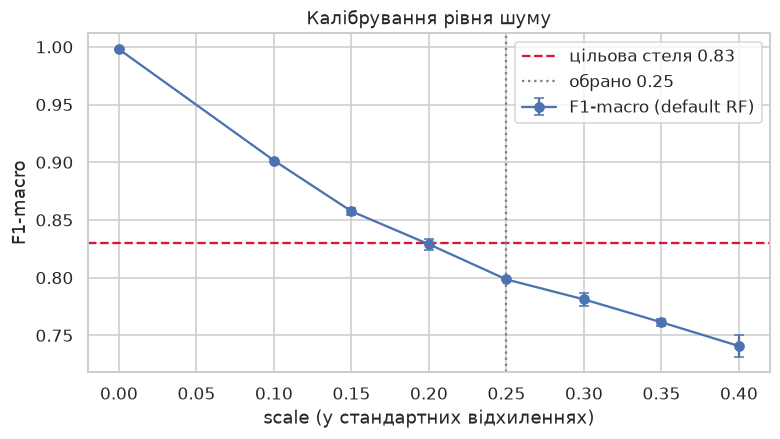

In [4]:
cv3 = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
scales = [0.0, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]

rows = []
for s in scales:
    t0 = time.perf_counter()
    scores = cross_val_score(build_model(noise_scale=s), X_train, y_train,
                             cv=cv3, scoring=SCORING, n_jobs=N_JOBS)
    rows.append({'noise_scale': s, 'f1_macro': scores.mean(),
                 'std': scores.std(), 'time_s': time.perf_counter() - t0})

calib = pd.DataFrame(rows)
display(calib.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(calib['noise_scale'], calib['f1_macro'], yerr=calib['std'],
            marker='o', capsize=3, label='F1-macro (default RF)')
ax.axhline(0.83, color='crimson', ls='--', label='цільова стеля 0.83')
ax.axvline(NOISE_SCALE, color='grey', ls=':', label=f'обрано {NOISE_SCALE}')
ax.set_xlabel('scale (у стандартних відхиленнях)')
ax.set_ylabel('F1-macro')
ax.set_title('Калібрування рівня шуму')
ax.legend()
plt.show()

Вибір: `NOISE_SCALE = 0.25` - базова модель дає ≈ 0.80, тобто нижче за 0.83, але залишається простір для покращення гіперпараметрами. Без шуму (`scale = 0`) задача вироджується у F1 ≈ 0.998 і всі методи оптимізації показують однаковий результат.

## 4. Етап 1. Baseline-модель

Типові гіперпараметри (n_estimators=100, max_depth без обмежень, max_features='sqrt', min_samples_leaf=1). Оцінка - 5-fold CV на train + окремий holdout.

CV (5-fold) F1-macro: 0.8026 +/- 0.0156
Holdout F1-macro:     0.8148
Час 5-fold CV:        1.9 s

                   precision    recall  f1-score   support

     Mild Deficit      0.685     0.716     0.700       661
    Moderate Debt      0.893     0.912     0.902      1472
 Optimal Recovery      0.848     0.753     0.798       458
Severe Sleep Debt      0.878     0.841     0.859       214

         accuracy                          0.834      2805
        macro avg      0.826     0.805     0.815      2805
     weighted avg      0.836     0.834     0.834      2805



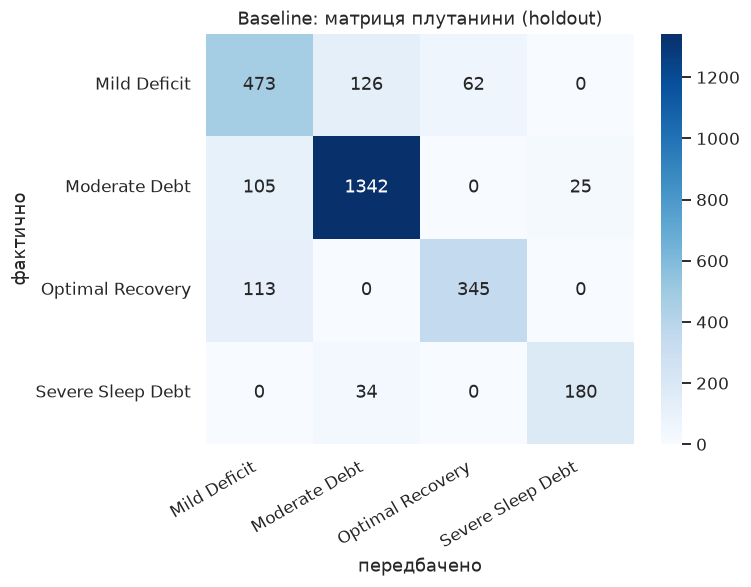

In [5]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

baseline = build_model()
t0 = time.perf_counter()
baseline_cv = cross_val_score(baseline, X_train, y_train, cv=cv5, scoring=SCORING, n_jobs=N_JOBS)
baseline_time = time.perf_counter() - t0

baseline.fit(X_train, y_train)
y_pred = baseline.predict(X_test)
baseline_holdout = f1_score(y_test, y_pred, average='macro')

print(f'CV (5-fold) F1-macro: {baseline_cv.mean():.4f} +/- {baseline_cv.std():.4f}')
print(f'Holdout F1-macro:     {baseline_holdout:.4f}')
print(f'Час 5-fold CV:        {baseline_time:.1f} s')
print()
print(classification_report(y_test, y_pred, digits=3))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_xlabel('передбачено')
ax.set_ylabel('фактично')
ax.set_title('Baseline: матриця плутанини (holdout)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

## 5. Етап 2. Порівняння методів оптимізації

Простір пошуку - 4 гіперпараметри (81 комбінація):

| параметр | значення |
|---|---|
| `n_estimators` | 100, 300, 500 |
| `max_depth` | 10, 20, None |
| `max_features` | 'sqrt', 'log2', 0.5 |
| `min_samples_leaf` | 1, 2, 4 |

Для коректного порівняння усі методи використовують однакові фолди `StratifiedKFold(3, shuffle=True, random_state=42)` і метрику `f1_macro`. Фіксується найкраще значення валідаційної метрики та час виконання.

In [6]:
param_grid = {
    'clf__n_estimators': [100, 300, 500],
    'clf__max_depth': [10, 20, None],
    'clf__max_features': ['sqrt', 'log2', 0.5],
    'clf__min_samples_leaf': [1, 2, 4],
}

n_configs = int(np.prod([len(v) for v in param_grid.values()]))
print(f'Комбінацій у повній сітці: {n_configs}')
print(f'Фітів для GridSearchCV:   {n_configs * cv3.get_n_splits()}')
print(f'Фітів для Random(20/50):  {20 * cv3.get_n_splits()} / {50 * cv3.get_n_splits()}')
print(f'Фітів для Optuna(20):     {20 * cv3.get_n_splits()}')

Комбінацій у повній сітці: 81
Фітів для GridSearchCV:   243
Фітів для Random(20/50):  60 / 150
Фітів для Optuna(20):     60


In [7]:
t0 = time.perf_counter()
grid_search = GridSearchCV(
    build_model(), param_grid, cv=cv3, scoring=SCORING, n_jobs=N_JOBS, refit=True
)
grid_search.fit(X_train, y_train)
grid_time = time.perf_counter() - t0

print(f'GridSearchCV: best CV F1-macro = {grid_search.best_score_:.4f}, час = {grid_time:.1f} s')
print(f'best params: {grid_search.best_params_}')

GridSearchCV: best CV F1-macro = 0.8065, час = 143.6 s
best params: {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__n_estimators': 500}


In [8]:
random_searches = {}
random_times = {}

for n_iter in (20, 50):
    t0 = time.perf_counter()
    rs = RandomizedSearchCV(
        build_model(),
        param_distributions=param_grid,
        n_iter=n_iter,
        cv=cv3,
        scoring=SCORING,
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE,
        refit=True,
    )
    rs.fit(X_train, y_train)
    random_searches[n_iter] = rs
    random_times[n_iter] = time.perf_counter() - t0
    print(f'RandomizedSearchCV n_iter={n_iter}: best CV F1-macro = {rs.best_score_:.4f}, '
          f'час = {random_times[n_iter]:.1f} s')

RandomizedSearchCV n_iter=20: best CV F1-macro = 0.8041, час = 31.5 s
RandomizedSearchCV n_iter=50: best CV F1-macro = 0.8048, час = 83.4 s


In [9]:
def optuna_objective(trial):
    params = {
        'clf__n_estimators': trial.suggest_categorical('n_estimators', param_grid['clf__n_estimators']),
        'clf__max_depth': trial.suggest_categorical('max_depth', param_grid['clf__max_depth']),
        'clf__max_features': trial.suggest_categorical('max_features', param_grid['clf__max_features']),
        'clf__min_samples_leaf': trial.suggest_categorical('min_samples_leaf', param_grid['clf__min_samples_leaf']),
    }
    model = clone(build_model()).set_params(params)
    scores = cross_val_score(model, X_train, y_train, cv=cv3, scoring=SCORING, n_jobs=N_JOBS)
    return scores.mean()


sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)
study = optuna.create_study(direction='maximize', sampler=sampler)
t0 = time.perf_counter()
study.optimize(optuna_objective, n_trials=20, show_progress_bar=False)
optuna_time = time.perf_counter() - t0

print(f'Optuna TPE (20 trials): best CV F1-macro = {study.best_value:.4f}, час = {optuna_time:.1f} s')
print(f'best params: {study.best_params}')

Optuna TPE (20 trials): best CV F1-macro = 0.8065, час = 127.6 s
best params: {'n_estimators': 500, 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1}


In [17]:
optuna_best_params = {'clf__' + k: v for k, v in study.best_params.items()}
optuna_best = clone(build_model()).set_params(optuna_best_params)
optuna_best.fit(X_train, y_train)

experiments = [
    ('GridSearchCV (full)', n_configs, grid_search.best_score_, grid_time, grid_search.best_params_),
    ('RandomSearch n=20', 20, random_searches[20].best_score_, random_times[20], random_searches[20].best_params_),
    ('RandomSearch n=50', 50, random_searches[50].best_score_, random_times[50], random_searches[50].best_params_),
    ('Optuna TPE n=20', 20, study.best_value, optuna_time, study.best_params),
]

fitted_models = {
    'GridSearchCV (full)': grid_search,
    'RandomSearch n=20': random_searches[20],
    'RandomSearch n=50': random_searches[50],
    'Optuna TPE n=20': optuna_best,
}

rows = []
for name, n_evals, cv_score, wall, params in experiments:
    holdout = f1_score(y_test, fitted_models[name].predict(X_test), average='macro')
    rows.append({
        'метод': name,
        'оцінок': n_evals,
        'CV F1-macro': round(cv_score, 4),
        'holdout F1': round(holdout, 4),
        'час, с': round(wall, 1),
        'час/оцінку, с': round(wall / n_evals, 2),
        'найкращі параметри': ', '.join(f'{k.replace("clf__", "")}={v}' for k, v in params.items()),
    })

results_df = pd.DataFrame(rows)
display(results_df.set_index('метод'))

,оцінок,CV F1-macro,holdout F1,"час, с","час/оцінку, с",найкращі параметри
метод,,,,,,
GridSearchCV (full),81,0.8065,0.8162,143.6,1.77,"max_depth=10, max_features=sqrt, min_samples_l..."
RandomSearch n=20,20,0.8041,0.8136,31.5,1.58,"n_estimators=300, min_samples_leaf=2, max_feat..."
RandomSearch n=50,50,0.8048,0.8165,83.4,1.67,"n_estimators=300, min_samples_leaf=2, max_feat..."
Optuna TPE n=20,20,0.8065,0.8162,127.6,6.38,"n_estimators=500, max_depth=10, max_features=s..."


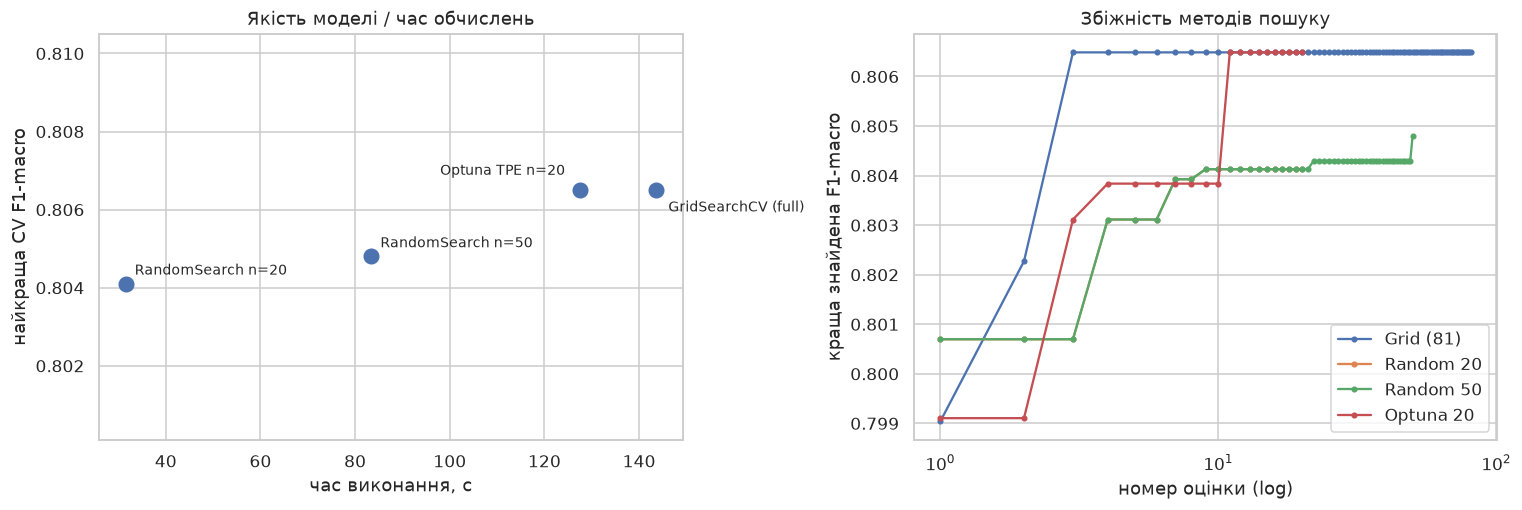

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# 1. Якість / час
ax = axes[0]
ax.scatter(results_df['час, с'], results_df['CV F1-macro'], s=90, zorder=3)
offsets = {'Optuna TPE n=20': (-10, 10), 'GridSearchCV (full)': (8, -14)}
for _, row in results_df.iterrows():
    dx, dy = offsets.get(row['метод'], (6, 6))
    ax.annotate(row['метод'], (row['час, с'], row['CV F1-macro']),
                textcoords='offset points', xytext=(dx, dy), fontsize=9,
                ha='right' if dx < 0 else 'left')
ax.set_xlabel('час виконання, с')
ax.set_ylabel('найкраща CV F1-macro')
ax.set_title('Якість моделі / час обчислень')
ax.set_ylim(results_df['CV F1-macro'].min() - 0.004, results_df['CV F1-macro'].max() + 0.004)

# 2. Збіжність: best-so-far
ax = axes[1]
for label, scores in [
    ('Grid (81)', grid_search.cv_results_['mean_test_score']),
    ('Random 20', random_searches[20].cv_results_['mean_test_score']),
    ('Random 50', random_searches[50].cv_results_['mean_test_score']),
    ('Optuna 20', [t.value for t in study.trials]),
]:
    scores = np.asarray(scores, dtype=float)
    ax.plot(np.arange(1, len(scores) + 1), np.maximum.accumulate(scores), marker='o', ms=3, label=label)
ax.set_xscale('log')
ax.set_xlabel('номер оцінки (log)')
ax.set_ylabel('краща знайдена F1-macro')
ax.set_title('Збіжність методів пошуку')
ax.legend()

plt.tight_layout()
plt.show()

## 6. Етап 3. Витік даних (Data Leakage)

Порівнюються три варіанти з однаковою фінальною моделлю:

1. Коректний пайплайн - препроцесинг і `SMOTE` живуть усередині `imblearn.Pipeline`, тому на кожному фолді вони бачать лише тренувальну частину.
2. Витік через ресемплінг - `SMOTE` застосовано до всього датасету, і лише потім виконано train/test split. Синтетичні точки інтерполюються між сусідами, тому частина тестових об'єктів стає майже копіями тренувальних.
3. «Витік» без витоку - масштабування й one-hot застосовані до всього датасету, але без ресемплінгу. Контрольний випадок: ці кроки не використовують `y`, а Random Forest інваріантний до масштабу, тому завищення тут бути не повинно.

In [13]:
rf_params = dict(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)

# 1. Коректно: SMOTE всередині пайплайна, refit на кожному фолді
correct_pipe = ImbPipeline([
    ('pre', build_preprocessor()),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('clf', RandomForestClassifier(rf_params)),
])
t0 = time.perf_counter()
correct_cv = cross_val_score(correct_pipe, X_train, y_train, cv=cv3, scoring=SCORING, n_jobs=N_JOBS)
correct_time = time.perf_counter() - t0
correct_pipe.fit(X_train, y_train)
correct_test = f1_score(y_test, correct_pipe.predict(X_test), average='macro')

# 2. Витік: препроцесинг + SMOTE на всьому датасеті, split після
pre_all = build_preprocessor()
Z_all = pre_all.fit_transform(X)
Z_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(Z_all, y)
Xtr_l, Xte_l, ytr_l, yte_l = train_test_split(
    Z_res, y_res, test_size=TEST_SIZE, stratify=y_res, random_state=RANDOM_STATE
)
leaky_model = RandomForestClassifier(rf_params).fit(Xtr_l, ytr_l)
leaky_test = f1_score(yte_l, leaky_model.predict(Xte_l), average='macro')
leaky_cv = cross_val_score(clone(leaky_model), Z_res, y_res, cv=cv3, scoring=SCORING, n_jobs=N_JOBS)

# 3. Контроль: лише масштабування/кодування на всьому датасеті
Z_pre = build_preprocessor().fit_transform(X)
Xtr_p, Xte_p, ytr_p, yte_p = train_test_split(
    Z_pre, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
pre_only_model = RandomForestClassifier(rf_params).fit(Xtr_p, ytr_p)
pre_only_test = f1_score(yte_p, pre_only_model.predict(Xte_p), average='macro')
pre_only_cv = cross_val_score(clone(pre_only_model), Z_pre, y, cv=cv3, scoring=SCORING, n_jobs=N_JOBS)

leak_df = pd.DataFrame([
    {'варіант': 'Коректний (pipeline per fold)', 'CV F1-macro': correct_cv.mean(), 'holdout F1': correct_test},
    {'варіант': 'Витік: SMOTE до split', 'CV F1-macro': leaky_cv.mean(), 'holdout F1': leaky_test},
    {'варіант': 'Масштабування до split', 'CV F1-macro': pre_only_cv.mean(), 'holdout F1': pre_only_test},
])
leak_df['Δ до коректного'] = leak_df['holdout F1'] - correct_test
display(leak_df.round(4).set_index('варіант'))

,CV F1-macro,holdout F1,Δ до коректного
варіант,,,
Коректний (pipeline per fold),0.8015,0.8129,0.0000
Витік: SMOTE до split,0.9095,0.9080,0.0950
Масштабування до split,0.8098,0.8096,-0.0034


Штучне завищення holdout-оцінки: +0.095 (0.908 проти 0.813)


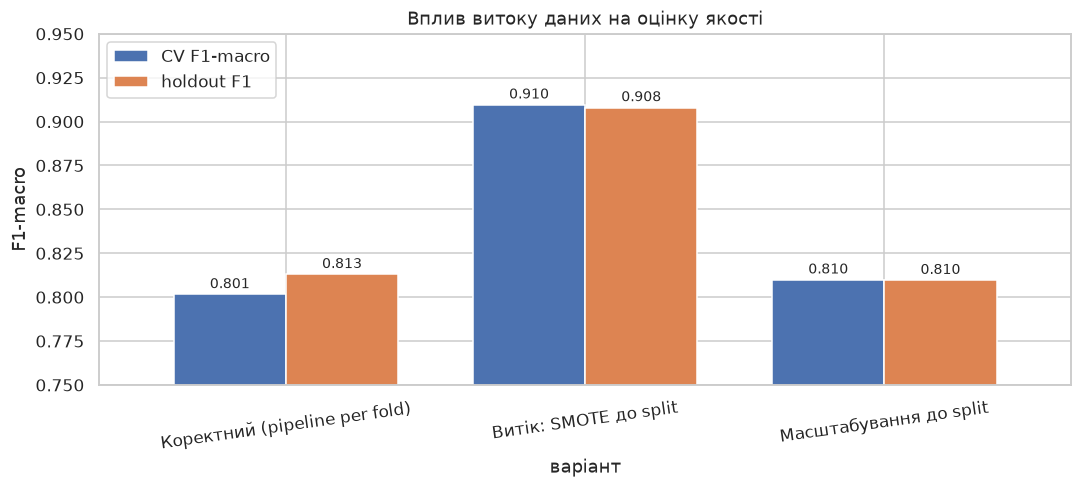

In [14]:
plot_df = leak_df.set_index('варіант')[['CV F1-macro', 'holdout F1']]
ax = plot_df.plot(kind='bar', figsize=(10, 4.6), rot=8, ylim=(0.75, 0.95), width=0.75)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=9, padding=2)
ax.set_ylabel('F1-macro')
ax.set_title('Вплив витоку даних на оцінку якості')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

print(f'Штучне завищення holdout-оцінки: +{leak_df.loc[1, "holdout F1"] - leak_df.loc[0, "holdout F1"]:.3f} '
      f'({leak_df.loc[1, "holdout F1"]:.3f} проти {leak_df.loc[0, "holdout F1"]:.3f})')

Висновок з експерименту: ресемплінг до розбиття завищує оцінку приблизно на +0.095 F1-macro - модель «впізнає» синтетичних близнюків тренувальних об'єктів у тесті. Натомість масштабування до розбиття тут нічого не завищує (`Δ ≈ 0`): це unsupervised-крок, а дерева нечутливі до монотонних перетворень ознак. Отже, витік - це не «препроцесинг до split» взагалі, а саме кроки, що використовують `y` (target encoding, відбір ознак, ресемплінг) або створюють дублікати між train і test.

## 7. Етап 4. Nested Cross-Validation

`best_score_` з `GridSearchCV` - оптимістична оцінка: гіперпараметри обиралися на тих самих фолдах, на яких потім мірялася якість. Nested CV розділяє ці дві задачі:

- зовнішня петля (K=5) - оцінює узагальнювальну здатність обраної процедури;
- внутрішня петля (K=3) - підбирає гіперпараметри всередині кожного зовнішнього train-фолду.

Процедура виконується на `X_train`, щоб тестовий `X_test` залишався повністю незайманим. Сітка звужена до 24 комбінацій (5 × 24 × 3 = 360 фітів) - компроміс між часом і точністю оцінки.

In [15]:
outer_cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
inner_cv = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

nested_grid = {
    'clf__n_estimators': [100, 300, 500],
    'clf__max_depth': [10, None],
    'clf__max_features': ['sqrt', 'log2'],
    'clf__min_samples_leaf': [1, 4],
}
n_nested_configs = int(np.prod([len(v) for v in nested_grid.values()]))
print(f'Комбінацій у внутрішній сітці: {n_nested_configs}, фітів: {5 * n_nested_configs * 3}')

rows = []
t0 = time.perf_counter()
for k, (tr_idx, te_idx) in enumerate(outer_cv.split(X_train, y_train), start=1):
    gs = GridSearchCV(build_model(), nested_grid, cv=inner_cv,
                       scoring=SCORING, n_jobs=N_JOBS, refit=True)
    gs.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    outer_f1 = f1_score(y_train.iloc[te_idx], gs.predict(X_train.iloc[te_idx]), average='macro')
    rows.append({
        'фолд': k,
        'inner best F1 (зміщена)': gs.best_score_,
        'outer F1 (незміщена)': outer_f1,
        'різниця': gs.best_score_ - outer_f1,
        'best params': ', '.join(f'{key.replace("clf__", "")}={v}' for key, v in gs.best_params_.items()),
    })
nested_time = time.perf_counter() - t0

nested_df = pd.DataFrame(rows)
display(nested_df.set_index('фолд').drop(columns='best params'))

inner_mean = nested_df['inner best F1 (зміщена)'].mean()
outer_mean = nested_df['outer F1 (незміщена)'].mean()
outer_std = nested_df['outer F1 (незміщена)'].std()

print(f'Середня inner best (оптимістична): {inner_mean:.4f}')
print(f'Середня outer (незміщена):         {outer_mean:.4f} +/- {outer_std:.4f}')
print(f'Оптимізм внутрішньої оцінки:       {inner_mean - outer_mean:+.4f}')
print(f'Час Nested CV:                     {nested_time:.1f} s')

Комбінацій у внутрішній сітці: 24, фітів: 360
Середня inner best (оптимістична): 0.7981
Середня outer (незміщена):         0.7985 +/- 0.0187
Оптимізм внутрішньої оцінки:       -0.0004
Час Nested CV:                     136.8 s


,inner best F1 (зміщена),outer F1 (незміщена),різниця
фолд,,,
1,0.805595,0.827201,-0.021606
2,0.796258,0.798594,-0.002336
3,0.797382,0.783047,0.014336
4,0.794790,0.802792,-0.008002
5,0.796271,0.780700,0.015571


,значення,тип,коментар
оцінка,,,
Baseline CV (5-fold),0.8026,незміщена,без підбору гіперпараметрів
GridSearchCV best_score_ (81),0.8065,зміщена,максимум по 81 конфігурації на тих самих фолдах
Nested CV outer (5-fold),0.7985,незміщена,std = 0.0187
Holdout,0.8162,контроль,найкраща модель етапу 2 на відкладеній вибірці


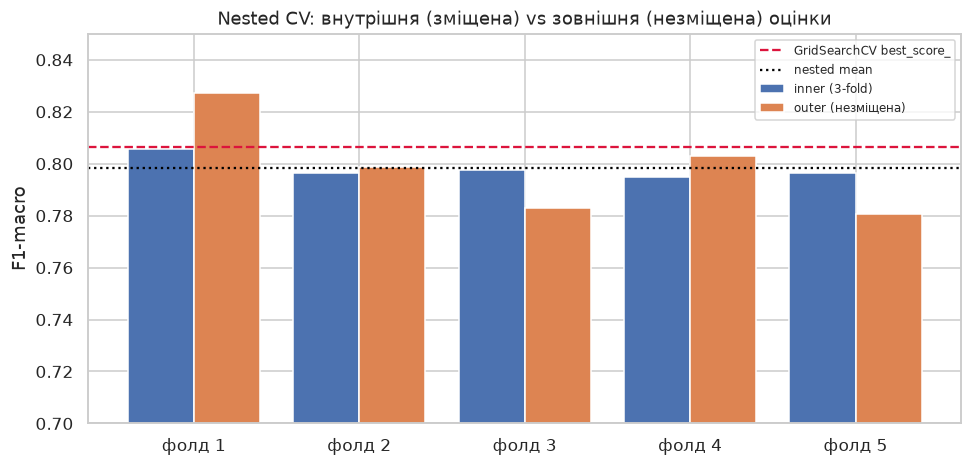

In [18]:
summary = pd.DataFrame([
    {'оцінка': 'Baseline CV (5-fold)', 'значення': baseline_cv.mean(), 'тип': 'незміщена', 'коментар': 'без підбору гіперпараметрів'},
    {'оцінка': 'GridSearchCV best_score_ (81)', 'значення': grid_search.best_score_, 'тип': 'зміщена', 'коментар': 'максимум по 81 конфігурації на тих самих фолдах'},
    {'оцінка': 'Nested CV outer (5-fold)', 'значення': outer_mean, 'тип': 'незміщена', 'коментар': f'std = {outer_std:.4f}'},
    {'оцінка': 'Holdout', 'значення': f1_score(y_test, grid_search.predict(X_test), average='macro'), 'тип': 'контроль', 'коментар': 'найкраща модель етапу 2 на відкладеній вибірці'},
])
display(summary.set_index('оцінка').round(4))

fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(nested_df))
ax.bar(x - 0.2, nested_df['inner best F1 (зміщена)'], width=0.4, label='inner (3-fold)')
ax.bar(x + 0.2, nested_df['outer F1 (незміщена)'], width=0.4, label='outer (незміщена)')
ax.axhline(grid_search.best_score_, color='crimson', ls='--', label='GridSearchCV best_score_')
ax.axhline(outer_mean, color='black', ls=':', label='nested mean')
ax.set_xticks(x, [f'фолд {i}' for i in nested_df['фолд']])
ax.set_ylim(0.70, 0.85)
ax.set_ylabel('F1-macro')
ax.set_title('Nested CV: внутрішня (зміщена) vs зовнішня (незміщена) оцінки')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Інтерпретація. Різниця між `inner best` та `outer` у середньому близька до нуля і повністю «тоне» у міжфолдовому розкиді (`std ≈ 0.019`): на 5 фолдах і 5695 об'єктах оцінка занадто шумна, щоб побачити оптимізм у 0.005–0.01. Але систематичне зміщення видно на рівні процедури: `best_score_ = 0.8065` (максимум по 81 конфігурації) проти незміщеної оцінки `0.7985` - це +0.008 штучного завищення, яке `GridSearchCV.best_score_` видає за «справжню» якість. Саме тому для фінального звіту беруть зовнішню петлю, а не `best_score_`.

## 8. Висновки

### 1. Методи оптимізації: якість проти часу

| метод | оцінок | CV F1-macro | час, с | висновок |
|---|---|---|---|---|
| Baseline (без підбору) | 1 | 0.8026 | 2 | відправна точка |
| GridSearchCV | 81 | 0.8065 | 144 | максимум якості, найдорожчий |
| RandomSearch n=20 | 20 | 0.8041 | 32 | 99.7 % якості grid за 22 % часу |
| RandomSearch n=50 | 50 | 0.8048 | 83 | приріст +0.0007 за +51 с - не варто |
| Optuna TPE n=20 | 20 | 0.8065 | 128 | та сама якість, що й grid, за меншу кількість оцінок |

- Grid Search дає найкращий результат, але його вартість зростає добутком розмірів простору: 4 параметри до 81 комбінація, п'ятий параметр із 3 значень зробив би 243 комбінації та ≈ 7 хв лише на один пошук.
- Random Search - найкраще співвідношення якість/час при малому бюджеті: 20 ітерацій уже потрапляють у добру область простору. Приріст від 20 до 50 ітерацій (0.8041 до 0.8048) не виправдовує додаткових 50 с.
- Bayesian (Optuna TPE) досягає тієї ж якості, що й повний grid, за 20 оцінок замість 81. У цьому експерименті він не виграв за часом, бо фіти дешеві: `GridSearchCV` паралелить конфігурації (16 ядер), а Optuna паралелить фолди всередині тріалу й витрачає час на overhead. Перевага TPE проявляється там, де один фіт коштує хвилини (великі дані, бустинг, нейромережі) - тоді важлива кількість оцінок, а не паралелізм.

### 2. Витік даних

- Ресемплінг (`SMOTE`) до розбиття завищує holdout-оцінку на +0.095 (0.813 до 0.908): синтетичні точки стоять між сусідами, тому тестова вибірка містить «майже копії» тренувальних об'єктів. Модель демонструє чудову якість, якої не буде в продакшені.
- Масштабування й one-hot до розбиття дали `Δ ≈ −0.003` - у межах шуму. Це не витік: кроки не використовують `y`, а дерева інваріантні до масштабу.
- Правило: усе, що залежить від `y` (target encoding, відбір ознак, ресемплінг, підбір гіперпараметрів), має жити всередині пайплайна і перераховуватися на кожному фолді. Для ресемплінгу - `imblearn.Pipeline`, а не ручний `SMOTE` перед split.

### 3. Незміщена оцінка (Nested CV)

- `GridSearchCV.best_score_ = 0.8065` - зміщена оцінка: це максимум по 81 конфігурації, порахований на тих самих фолдах, на яких потім звітується якість.
- Незміщена оцінка із зовнішньої петлі: 0.7985 ± 0.0187, тобто оптимізм `best_score_` ≈ +0.008.
- Різниця між `inner best` та `outer` у межах окремих фолдів коливається від −0.022 до +0.016 і в середньому близька до нуля: на 5 фолдах і 5695 об'єктах розкид (`std ≈ 0.019`) більший за сам ефект. Практичний висновок: не варто інтерпретувати різницю моделей меншу за ~0.02 F1, вона не відрізняється від шуму фолдів.

### 4. Головний висновок

Підбір гіперпараметрів дав +0.004 F1-macro над baseline (0.8026 до 0.8065), тоді як внесений шум коштує ≈ 0.20 F1 (0.998 до 0.80). Тобто на цьому датасеті якість обмежена якістю даних, а не гіперпараметрами: жоден пошук не відновить інформацію, якої в ознаках немає. Для реальних задач з обмеженими ресурсами оптимальна стратегія - `RandomizedSearchCV` на 20–30 ітераціях (або Optuna з pruning для дорогих моделей) і nested CV лише для фінальної оцінки, а не для кожного проміжного експерименту.